# Redes neurais na prática: Iris e MNIST

**Física Computacional · PRCCOMP · Prof. Gustavo Voltani von Atzingen · IFSP Piracicaba**

Na aula de introdução ao aprendizado de máquina, calculamos a saída de um
neurônio, medimos o erro e corrigimos os pesos. Agora vamos usar o **TensorFlow**
para os cálculos e o **Keras** para montar e treinar redes em camadas.

O objetivo é classificar flores a partir de quatro medidas e dígitos a partir
dos pixels de uma imagem. Nos dois casos, usamos **redes densas**, com uma
camada escondida. As células são sequenciais: execute de cima para baixo.

<a id="preparacao"></a>
## Preparação

No **Google Colab**, abra este notebook e execute as células com Shift+Enter.
Uma sessão de CPU é suficiente. Para rodar localmente, use Python 3.12 e instale:

```bash
python -m pip install tensorflow scikit-learn matplotlib notebook
python -m notebook
```

O Iris vem com o scikit-learn; o MNIST será baixado na primeira execução.
O arquivo já contém os resultados de uma execução, que podem ser lidos sem
treinar novamente. A semente abaixo ajuda a repetir o experimento; versões
e equipamentos diferentes ainda podem produzir pequenas diferenças.

In [1]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

keras.utils.set_random_seed(42)
plt.rcParams.update({"figure.figsize": (6, 4), "font.size": 12})
print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)

I0000 00:00:1792791585.406296 1338475 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792791585.406572 1338475 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792791588.143519 1338475 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792791588.143765 1338475 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow: 2.21.0 | Keras: 3.15.1


<a id="iris"></a>
## 1. Iris: quatro números entram, uma espécie sai

O [Iris](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html)
contém **150 flores**, sendo 50 de cada espécie: *setosa*, *versicolor* e *virginica*.
Cada linha tem quatro medidas em centímetros, nesta ordem:

1. Comprimento da sépala.
2. Largura da sépala.
3. Comprimento da pétala.
4. Largura da pétala.

**X** guarda as entradas; **y** guarda os rótulos corretos: 0, 1 ou 2.
Esses números identificam espécies, não uma ordem de grandeza.
A seguir vemos uma flor de cada classe.

In [2]:
iris = load_iris()
X = iris.data
y = iris.target

print("Formato de X:", X.shape)
print("Medidas (cm):\n", X[[0, 50, 100]])
print("Rótulos:", y[[0, 50, 100]])
print("Espécies:", iris.target_names)

Formato de X: (150, 4)
Medidas (cm):
 [[5.1 3.5 1.4 0.2]
 [7.  3.2 4.7 1.4]
 [6.3 3.3 6.  2.5]]
Rótulos: [0 1 2]
Espécies: ['setosa' 'versicolor' 'virginica']


### 1.1 Separar os dados antes de treinar

Reservamos **90 flores para treino, 30 para validação e 30 para teste**.
O treino ajusta os pesos; a validação acompanha o aprendizado e permite
comparar escolhas; o teste fica guardado para a avaliação final.

`stratify=y` mantém a proporção das três espécies em cada parte.
No segundo corte, 25% das 120 flores restantes são 30 flores.

In [3]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_treino, X_val, y_treino, y_val = train_test_split(
    X_treino, y_treino, test_size=0.25, random_state=42, stratify=y_treino
)
print("Treino, validação e teste:", len(y_treino), len(y_val), len(y_teste))

Treino, validação e teste: 90 30 30


### 1.2 Olhar duas medidas

O gráfico mostra somente as flores de **treino**, usando as duas medidas
da pétala. Cores e símbolos identificam as espécies. A rede receberá as
**quatro** medidas, mesmo que o gráfico mostre apenas duas.

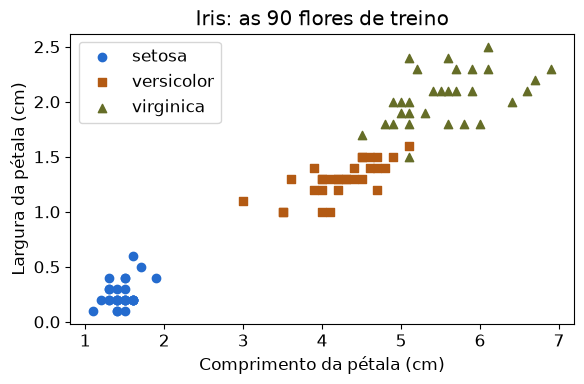

In [4]:
for classe, cor, simbolo in zip(range(3), ["#246bce", "#b35a13", "#656d27"], ["o", "s", "^"]):
    flores = X_treino[y_treino == classe]
    plt.scatter(flores[:, 2], flores[:, 3], color=cor, marker=simbolo,
                label=iris.target_names[classe])
plt.xlabel("Comprimento da pétala (cm)")
plt.ylabel("Largura da pétala (cm)")
plt.title("Iris: as 90 flores de treino")
plt.legend()
plt.tight_layout()
plt.show()

### 1.3 Colocar as medidas em escalas comparáveis

Para cada coluna, subtraímos a média e dividimos pelo desvio padrão:

$$x_{\mathrm{padronizado}} = \frac{x-\mu_{\mathrm{treino}}}{\sigma_{\mathrm{treino}}}.$$

`axis=0` calcula uma média e um desvio para cada uma das quatro medidas.
Usamos **somente o treino** para calcular esses valores. Validação, teste
e flores novas passam pela mesma transformação, sem recalcular a média.

In [5]:
media = X_treino.mean(axis=0)
desvio = X_treino.std(axis=0)

X_treino = (X_treino - media) / desvio
X_val = (X_val - media) / desvio
X_teste = (X_teste - media) / desvio

### 1.4 Montar a rede com Keras

**4 entradas → 8 neurônios na camada escondida → 3 saídas.**

- `Input(shape=(4,))`: cada flor tem quatro entradas.
- `Dense(8)`: cada um dos oito neurônios recebe as quatro entradas,
  aprende seus próprios pesos e um bias.
- `relu`: aplica a ativação $\max(0,z)$ à soma ponderada $z$.
- `Dense(3, activation="softmax")`: produz três probabilidades que somam 1,
  uma para cada espécie. A maior define a classificação.

`Sequential` coloca essas camadas em sequência. A camada escondida possui
$4\times 8+8=40$ parâmetros e a saída $8\times 3+3=27$: **67 parâmetros treináveis**.
São as mesmas somas ponderadas da aula anterior, agora conectadas em camadas.

In [6]:
modelo_iris = keras.Sequential([
    keras.Input(shape=(4,)),
    keras.layers.Dense(8, activation="relu"),
    keras.layers.Dense(3, activation="softmax"),
])
modelo_iris.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 67 (268.00 B)

 Trainable params: 67 (268.00 B)

 Non-trainable params: 0 (0.00 B)

### 1.5 Escolher a perda e treinar

`compile` configura o treinamento; ainda não altera os pesos.
`sparse_categorical_crossentropy` compara as probabilidades com o rótulo
inteiro correto. **Sparse** permite usar 0, 1 e 2 diretamente.
`adam` é o otimizador que usa os gradientes para atualizar os pesos;
`accuracy` mede a fração de classificações corretas.

`fit` repete propagação, cálculo da perda e correção por backpropagation.
Uma **época** percorre o treino inteiro. `batch_size=16` reúne até 16 flores
por atualização. A validação é avaliada ao final de cada época e não ajusta
os pesos. `verbose=0` evita imprimir 150 linhas de progresso.

Na aula anterior usamos erro quadrático com sigmoide; aqui a perda é a
entropia cruzada com softmax. O princípio de aprender com o gradiente continua.

In [7]:
modelo_iris.compile(
    optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"]
)
historico_iris = modelo_iris.fit(
    X_treino, y_treino, epochs=150, batch_size=16,
    validation_data=(X_val, y_val), verbose=0
)

### 1.6 Acompanhar o aprendizado

A perda mede o desacordo entre probabilidades e rótulos; **não é uma
porcentagem de erros**. Quanto menor, melhor para esse objetivo.
Compare treino e validação: queda no treino acompanhada de subida persistente
na validação é um sinal de sobreajuste (*overfitting*).

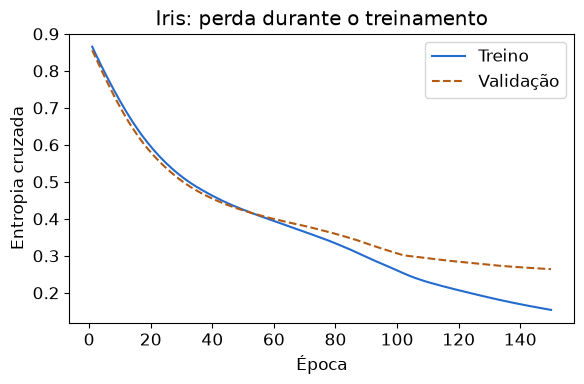

In [8]:
epocas = range(1, len(historico_iris.history["loss"]) + 1)
plt.plot(epocas, historico_iris.history["loss"], color="#246bce", label="Treino")
plt.plot(epocas, historico_iris.history["val_loss"], "--", color="#b35a13", label="Validação")
plt.xlabel("Época")
plt.ylabel("Entropia cruzada")
plt.title("Iris: perda durante o treinamento")
plt.legend()
plt.tight_layout()
plt.show()

### 1.7 Avaliar no teste separado

`evaluate` usa as 30 flores que ficaram guardadas. A acurácia é uma medida
desse pequeno conjunto, não uma garantia para toda flor encontrada no mundo.
Se mudar a arquitetura ou as épocas, compare as opções na **validação**;
não escolha a rede pelo resultado do teste.

In [9]:
perda, acuracia = modelo_iris.evaluate(X_teste, y_teste, verbose=0)
print(f"Acurácia no teste Iris: {acuracia:.1%} ({len(y_teste)} flores)")

Acurácia no teste Iris: 86.7% (30 flores)


### 1.8 Classificar uma flor pelas medidas

Digite quatro medidas em centímetros, na mesma ordem do início.
Os valores abaixo são **ilustrativos**, não uma nova amostra independente
para avaliar a rede. A linha precisa ser padronizada com a média e o desvio
que guardamos do treino. `predict` aplica os pesos aprendidos, sem treiná-los.

In [10]:
nova_flor = [[5.2, 3.4, 1.5, 0.2]]
probabilidades = modelo_iris.predict((nova_flor - media) / desvio, verbose=0)[0]
print("Espécies:", iris.target_names)
print("Probabilidades:", probabilidades.round(3))
print("Previsão:", iris.target_names[probabilidades.argmax()])

Espécies: ['setosa' 'versicolor' 'virginica']
Probabilidades: [0.995 0.005 0.   ]
Previsão: setosa


<a id="mnist"></a>
## 2. MNIST: uma imagem também é um conjunto de números

O [MNIST](https://keras.io/api/datasets/mnist/) reúne dígitos manuscritos de
**0 a 9**, em imagens de **28 × 28 pixels**, em tons de cinza. O Keras fornece
60.000 imagens para desenvolvimento e 10.000 para teste.

Cada pixel varia de 0 a 255. Dividir por 255 coloca as entradas entre 0 e 1.
Essa escala é conhecida de antemão e não precisa ser estimada com os dados.
A nova entrada terá 784 números em vez dos quatro do Iris.

In [11]:
(X_mnist, y_mnist), (X_teste_mnist, y_teste_mnist) = keras.datasets.mnist.load_data()
X_mnist = X_mnist / 255.0
X_teste_mnist = X_teste_mnist / 255.0
print("Desenvolvimento:", X_mnist.shape, "| Teste:", X_teste_mnist.shape)

Desenvolvimento: (60000, 28, 28) | Teste: (10000, 28, 28)


### 2.1 Ver a entrada e seu rótulo

Escolha um índice e observe a imagem. O rótulo é a resposta correta que
acompanha essa amostra; ainda não é uma previsão da rede.

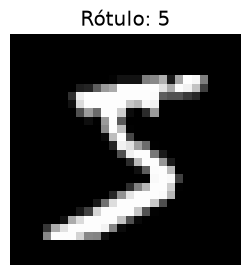

In [12]:
indice = 0
plt.figure(figsize=(3, 3))
plt.imshow(X_mnist[indice], cmap="gray", vmin=0, vmax=1)
plt.title(f"Rótulo: {y_mnist[indice]}")
plt.axis("off")
plt.show()

### 2.2 Montar uma rede densa para imagens

**28 × 28 pixels → 784 entradas → 32 neurônios → 10 saídas.**

`Flatten` reorganiza a matriz em um vetor: não aprende pesos e não aplica
filtros. As camadas `Dense` fazem o mesmo trabalho do exemplo anterior.
Usamos somente conexões densas, **sem convoluções**.

In [13]:
modelo_mnist = keras.Sequential([
    keras.Input(shape=(28, 28)),
    keras.layers.Flatten(),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])
modelo_mnist.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,450 (99.41 KB)

 Trainable params: 25,450 (99.41 KB)

 Non-trainable params: 0 (0.00 B)

### 2.3 Treinar com as mesmas etapas

A perda e o otimizador são os mesmos. `validation_split=0.1` reserva as
últimas **6.000** imagens de desenvolvimento para validação, antes de
embaralhar o treino: **54.000 treinam os pesos** e **10.000 continuam no teste**.
As imagens do MNIST não estão agrupadas por classe nessa partição.
`verbose=2` imprime somente uma linha de resultado por época.

In [14]:
modelo_mnist.compile(
    optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"]
)
historico_mnist = modelo_mnist.fit(
    X_mnist, y_mnist, epochs=5, validation_split=0.1, verbose=2
)

Epoch 1/5


1688/1688 - 1s - 658us/step - accuracy: 0.8970 - loss: 0.3697 - val_accuracy: 0.9493 - val_loss: 0.1832


Epoch 2/5


1688/1688 - 1s - 455us/step - accuracy: 0.9433 - loss: 0.1939 - val_accuracy: 0.9568 - val_loss: 0.1482


Epoch 3/5


1688/1688 - 1s - 463us/step - accuracy: 0.9549 - loss: 0.1531 - val_accuracy: 0.9627 - val_loss: 0.1301


Epoch 4/5


1688/1688 - 1s - 495us/step - accuracy: 0.9618 - loss: 0.1291 - val_accuracy: 0.9665 - val_loss: 0.1187


Epoch 5/5


1688/1688 - 1s - 437us/step - accuracy: 0.9672 - loss: 0.1124 - val_accuracy: 0.9677 - val_loss: 0.1132


### 2.4 Comparar treino e validação

Leia as curvas como no Iris. O gráfico mostra a evolução da perda;
o teste só entra na próxima célula. As duas curvas não precisam coincidir:
são conjuntos diferentes e a perda do treino é medida enquanto os pesos mudam.

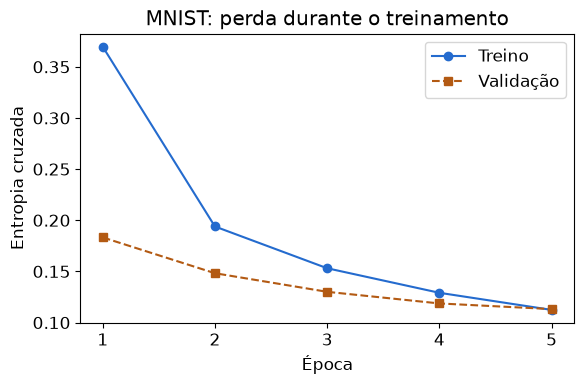

In [15]:
epocas = range(1, len(historico_mnist.history["loss"]) + 1)
plt.plot(epocas, historico_mnist.history["loss"], "o-", color="#246bce", label="Treino")
plt.plot(epocas, historico_mnist.history["val_loss"], "s--", color="#b35a13", label="Validação")
plt.xticks(list(epocas))
plt.xlabel("Época")
plt.ylabel("Entropia cruzada")
plt.title("MNIST: perda durante o treinamento")
plt.legend()
plt.tight_layout()
plt.show()

### 2.5 Avaliar e prever

A saída possui dez probabilidades, na ordem dos dígitos de 0 a 9.
`argmax(axis=1)` escolhe a maior em cada linha, produzindo uma previsão por imagem.

In [16]:
perda, acuracia = modelo_mnist.evaluate(X_teste_mnist, y_teste_mnist, verbose=0)
print(f"Acurácia no teste MNIST: {acuracia:.1%} ({len(y_teste_mnist)} imagens)")

probabilidades_mnist = modelo_mnist.predict(X_teste_mnist, verbose=0)
previsoes_mnist = probabilidades_mnist.argmax(axis=1)

Acurácia no teste MNIST: 96.2% (10000 imagens)


Probabilidades de 0 a 9: [0.    0.    0.    0.002 0.    0.    0.    0.997 0.    0.   ]


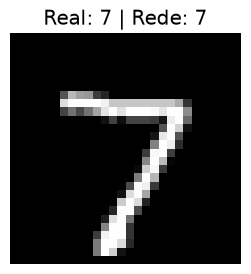

In [17]:
indice = 0
print("Probabilidades de 0 a 9:", probabilidades_mnist[indice].round(3))
plt.figure(figsize=(3, 3))
plt.imshow(X_teste_mnist[indice], cmap="gray", vmin=0, vmax=1)
plt.title(f"Real: {y_teste_mnist[indice]} | Rede: {previsoes_mnist[indice]}")
plt.axis("off")
plt.show()

### 2.6 Olhar também os erros

Uma acurácia alta ainda deixa erros. Abaixo aparecem os **primeiros seis
erros na ordem do teste**, com o rótulo real e a previsão. Alguns dígitos
se parecem; reconhecer o MNIST não garante reconhecer qualquer foto de
um número, com outro fundo, escala ou iluminação.

Erros: 382 em 10000 imagens de teste


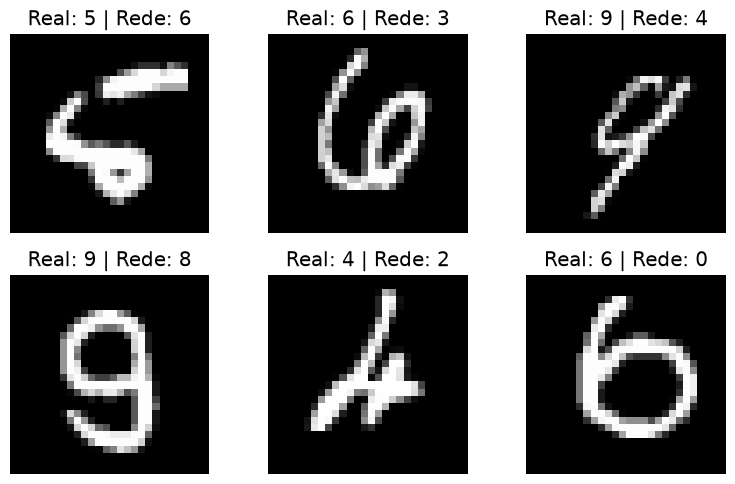

In [18]:
erros = (previsoes_mnist != y_teste_mnist).nonzero()[0]
print(f"Erros: {len(erros)} em {len(y_teste_mnist)} imagens de teste")
plt.figure(figsize=(8, 5))
for posicao, indice in enumerate(erros[:6]):
    plt.subplot(2, 3, posicao + 1)
    plt.imshow(X_teste_mnist[indice], cmap="gray", vmin=0, vmax=1)
    plt.title(f"Real: {y_teste_mnist[indice]} | Rede: {previsoes_mnist[indice]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

<a id="experimente"></a>
## 3. Experimente e explique

Faça uma mudança por vez e use a **validação** para comparar:

1. No Iris, troque os 8 neurônios por 2 e depois por 16. Compare a perda de
   validação e o número de parâmetros em `summary()`.
2. Treine o Iris por 20 épocas em vez de 150. A curva já parou de melhorar?
3. No MNIST, troque os 32 neurônios por 8. Observe a validação.
4. Por que usamos três saídas no Iris e dez no MNIST? Por que o Iris
   não precisa de `Flatten`?

**Para cada comparação, reinicie o kernel e execute tudo novamente.**
Executar só `fit` continua treinando os pesos anteriores; a padronização
também não deve ser aplicada duas vezes. Durante as experiências, pule as
células de avaliação/previsão no teste (1.7, 2.5 e 2.6). No final, avalie uma
vez a configuração escolhida. Como esta aula já mostra resultados de teste,
novas escolhas feitas olhando esses resultados deixam de ser uma avaliação
independente: seriam necessários novos dados para confirmá-las.

O procedimento foi o mesmo nos dois exemplos: preparar entradas e rótulos,
montar camadas, configurar a perda, treinar, avaliar e prever.
O Keras calculou os gradientes e atualizou os pesos; nós escolhemos os dados,
a arquitetura e a pergunta que a rede pode responder.

<a id="referencias"></a>
## Referências

- [Aula anterior: introdução ao aprendizado de máquina](https://atzingen.github.io/disciplinas/topicos/04-introducao-ml/).
- [Iris no scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html).
- [Iris: origem do conjunto no UCI](https://archive.ics.uci.edu/dataset/53/iris).
- [MNIST no Keras: dados e licença](https://keras.io/api/datasets/mnist/).
- [Keras: modelo Sequential](https://keras.io/guides/sequential_model/).
- [Keras: compile, fit, evaluate e predict](https://keras.io/api/models/model_training_apis/).
- [TensorFlow: primeira rede para MNIST](https://www.tensorflow.org/tutorials/quickstart/beginner).

Material didático elaborado para esta disciplina a partir dessas APIs e datasets.
O MNIST é disponibilizado sob CC BY-SA 3.0, conforme a documentação do Keras;
as imagens exibidas mantêm essa atribuição a Yann LeCun e Corinna Cortes.